In [107]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Part B: Designing the next AAA title (Deliverable #1, model)

**The question.** A studio deciding how to make its next AAA title doesn't need a forecast for films that already exist. It needs a **film to make**. A classifier can only score a film you hand it, so we put one inside a search:

```
              ┌────────────── feedback: scores + what drove them ──────────────┐
              ▼                                                                  │
   LLM generator  ──►  concepts (JSON)  ──►  checks  ──►  judge (classifier)  ──┘
   (GPT-6 Sol)         title, premise,       novelty,     P(AAA hit) + range
                       genres, budget,       familiarity  + drivers
                       real director/leads
```

- **Generator** (LLM): creative, knows culture, proposes concepts. It never grades itself.
- **Judge** (classifier): trained on past films' **pre-release** features to predict a Part A **AAA hit**; backtested on later years; calibrated.
- **Loop** (OPRO, Yang et al., ICLR 2024): scored concepts go back to the generator, worst to best, with *why* each scored as it did.
- **Guardrails** against gaming a learned judge: a novelty filter, a familiarity check, uncertainty bands, and a no-feedback control arm.

**Decisions (agreed):** design a *new* film · *original* stories only · *real* directors and actors, chosen from track-record tables.

| Section | What it does |
|---|---|
| 1 | Setup and LLM configuration (mock mode works with no keys) |
| 2 | Talent track records, as of each film's release |
| 3 | Pre-release features and plot embeddings |
| 4 | The judge: backtest, calibration, what it relies on |
| 5 | The prompts, rendered |
| 6 | The loop and its control arm |
| 7 | The pitch: the final concept portfolio |
| 8 | Baseline: can an LLM alone predict hits? |
| 9 | Cost, caveats, summary |

One-command version: `python scripts/run_part_b.py`.

## 1. Setup

**LLM settings** come from environment variables or a `.env` file in the project root; copy `.env.example`. With no settings, everything runs in **mock mode**: an offline stand-in returns random, schema-valid concepts so you can check the plumbing. Mock concepts are placeholders, never results.

`DEMO = True` uses the synthetic data (setup check only).

In [12]:
DEMO = False   # True = synthetic data + mock LLM, for checking your setup only
MODE = None    # None = follow LLM_MODE / .env ("auto"); or "mock" / "live"

import logging, sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "nextaaa").exists())
sys.path.insert(0, str(ROOT / "src"))

from nextaaa import hits, plots as plots_a
from nextaaa.config import AnalysisConfig, PartBConfig, Paths
from nextaaa.partb import dataset, llm, llm_baseline, loop, plots, prompts, scorer, talent
from nextaaa.partb.pipeline import load_labels, pitch_card

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s", force=True)
for noisy in ("nextaaa.clustering", "httpx", "nextaaa._cache"):
    logging.getLogger(noisy).setLevel(logging.WARNING)
pd.set_option("display.max_columns", 40, "display.width", 180, "display.float_format", "{:,.3f}".format)

In [14]:
import io, struct, zlib
import numpy as np

bad = next(paths.cache_dir.glob("embeddings__*.npz"))   # the damaged cache
print(bad, f"{bad.stat().st_size / 1e6:.1f} MB")
raw = bad.read_bytes()

out, pos = {}, 0
while (pos := raw.find(b"PK\x03\x04", pos)) >= 0:        # each entry starts with this marker
    try:
        method, = struct.unpack_from("<H", raw, pos + 8)
        name_len, extra_len = struct.unpack_from("<HH", raw, pos + 26)
        name = raw[pos + 30: pos + 30 + name_len].decode()
        start = pos + 30 + name_len + extra_len
        if name.endswith(".npy"):
            chunk = raw[start: start + (1 << 16)]          # 64 KB: more than one vector needs
            if method == 8:                                # compressed entry
                chunk = zlib.decompressobj(-15).decompress(chunk)
            out[name[:-4]] = np.lib.format.read_array(io.BytesIO(chunk))
    except Exception:
        pass                                               # the cut-off last entry, or a false match
    pos += 4

print(f"Recovered {len(out):,} embeddings")
bad.replace(bad.with_name(bad.name + ".corrupt"))          # keep the damaged file, just in case
np.savez(bad, **out)

C:\Users\user\Documents\next-aaa-title-part-a\next-aaa-title\data\cache\embeddings__text-embedding-3-large.npz 54.9 MB
Recovered 6,963 embeddings


In [16]:
cfg, bcfg = AnalysisConfig(), PartBConfig()
if DEMO:
    from nextaaa.synthetic import (make_synthetic_cpi, make_synthetic_imdb, make_synthetic_movielens,
                                   make_synthetic_tmdb)
    demo = ROOT / "data" / "synthetic"
    if not (demo / "imdb" / "title.basics.tsv.gz").exists():
        make_synthetic_imdb(demo / "imdb"); make_synthetic_movielens(demo / "imdb", demo / "ml-20m")
    if not (demo / "tmdb").exists():
        make_synthetic_tmdb(demo / "imdb", demo / "tmdb"); make_synthetic_cpi(demo / "cpi")
    paths = Paths.resolve(demo / "imdb", demo / "ml-20m", demo / "cache", ROOT / "outputs_demo",
                          demo / "tmdb", demo / "cpi")
    cfg = replace(cfg, min_votes_for_clustering=200, movielens_min_ratings_per_year=500,
                  movielens_min_ratings_for_std=20, dbscan_min_samples=10)
    MODE = "mock"
else:
    paths = Paths.resolve()

OUT = paths.output_dir / "partb"
FIG, TAB = OUT / "figures", OUT / "tables"
for d in (FIG, TAB): d.mkdir(parents=True, exist_ok=True)
(OUT / "llm_log.jsonl").unlink(missing_ok=True)
def save(fig, name):
    plots_a.save(fig, FIG / f"{name}.png"); return fig

clients = llm.get_clients(ROOT, paths.cache_dir, OUT / "llm_log.jsonl", MODE)
clients.describe()

INFO nextaaa.partb.llm: GENERATOR -> gpt-6-sol at https://api.openai.com/v1
INFO nextaaa.partb.llm: BASELINE  -> gpt-5-mini at https://api.openai.com/v1
INFO nextaaa.partb.llm: EMBEDDING -> text-embedding-3-large at https://api.openai.com/v1


{'mode': 'live',
 'generator': 'GENERATOR:gpt-6-sol',
 'judge': 'BASELINE:gpt-5-mini',
 'embeddings': 'api:text-embedding-3-large'}

## 2. Talent track records

Part A v2's labels say which past films were AAA hits. From them we compute each **director's** and **lead actor's** record **as of each film's release**: only films from *earlier* years count. Otherwise a director who later made three hits would look great in their debut year too, and the judge would be learning from the future.

Rates are **smoothed**: (hits + 2 × base rate) / (films + 2), so "1 hit in 1 film" is not "100%".

In [18]:
labels = load_labels(paths, cfg)           # runs Part A v2 first if its labels are missing
credits = talent.load_credits(paths, cfg, set(labels["tconst"]), ("director", "actor", "actress"))
people = talent.load_people(paths, set(credits["nconst"]))
pf = talent.person_film_table(labels, credits, bcfg.leads_per_film)
records = talent.asof_records(pf, labels, bcfg.track_record_prior_strength)
track = talent.film_track_features(pf, records)
print(f"{len(labels):,} films; {labels['has_finance'].sum():,} with money data; "
      f"{labels['is_aaa_hit'].sum():,} AAA hits")
track.describe().T[["mean", "50%", "max"]]

46,129 films; 7,959 with money data; 113 AAA hits


,mean,50%,max
dir_prior_films,2.649,1.000,50.000
dir_prior_aud_hits,0.214,0.000,21.000
dir_aud_rate,0.053,0.046,0.809
dir_prior_money_films,0.690,0.000,36.000
dir_prior_aaa_hits,0.019,0.000,9.000
dir_aaa_rate,0.015,0.014,0.548
dir_mean_audience_score,54.806,55.903,99.872
lead_prior_films,4.756,2.000,84.500
lead_aud_rate,0.054,0.042,0.673
lead_aaa_rate,0.015,0.014,0.392


### The shortlists the generator must cast from

Alive (no death year on IMDb), active in the last `shortlist_active_within_years` years, with at least `shortlist_min_prior_films` films, ranked by smoothed AAA-hit rate. The LLM sees these tables and must answer with their **ids** (D01…, A01…), so it can't invent people, and every concept can be scored.

In [20]:
now = cfg.max_year
directors = talent.shortlist(pf, labels, people, "director", now, bcfg, bcfg.shortlist_directors, "D")
actors = talent.shortlist(pf, labels, people, "lead", now, bcfg, bcfg.shortlist_actors, "A")
directors.to_csv(TAB / "shortlist_directors.csv", index=False); actors.to_csv(TAB / "shortlist_actors.csv", index=False)
cols = ["id", "primaryName", "prior_films", "prior_aaa_hits", "prior_aaa_rate", "prior_aud_hits", "top_genres", "last_year"]
display(directors[cols].head(10)); display(actors[cols].head(10))

,id,primaryName,prior_films,prior_aaa_hits,prior_aaa_rate,prior_aud_hits,top_genres,last_year
0,D01,Kyle Balda,3,3,0.606,3,"Animation, Comedy, Adventure",2022
1,D02,Pierre Coffin,4,3,0.505,4,"Adventure, Comedy, Animation",2017
2,D03,James Cameron,12,4,0.366,8,"Adventure, Action, Sci-Fi",2025
3,D04,Haruo Sotozaki,8,1,0.343,6,"Action, Animation, Adventure",2025
4,D05,David F. Sandberg,5,2,0.338,3,"Horror, Mystery, Action",2025
5,D06,Chris Renaud,6,2,0.290,3,"Adventure, Comedy, Animation",2024
6,D07,Jennifer Lee,2,1,0.257,2,"Adventure, Animation, Comedy",2019
7,D08,Tim Miller,2,1,0.257,2,"Action, Sci-Fi, Adventure",2019
8,D09,Aneesh Chaganty,2,1,0.257,2,"Mystery, Drama, Horror",2020
9,D10,Florian Henckel von Donnersmarck,3,1,0.257,2,"Thriller, Drama, Romance",2018


,id,primaryName,prior_films,prior_aaa_hits,prior_aaa_rate,prior_aud_hits,top_genres,last_year
0,A01,Mark Hamill,11,3,0.433,3,"Adventure, Action, Fantasy",2023
1,A02,Rishab Shetty,5,1,0.343,4,"Drama, Thriller, Adventure",2025
2,A03,Akari Kitô,2,1,0.343,2,"Animation, Action, Adventure",2021
3,A04,Miyu Irino,4,1,0.343,2,"Animation, Adventure, Drama",2018
4,A05,Zendaya,4,1,0.343,2,"Adventure, Drama, Action",2024
5,A06,Natsuki Hanae,15,1,0.343,5,"Animation, Action, Adventure",2025
6,A07,Meher Vij,2,1,0.343,1,"Drama, Comedy, Music",2022
7,A08,Sakshi Tanwar,3,1,0.343,1,"Drama, Comedy, Biography",2024
8,A09,Aya Hisakawa,4,1,0.343,1,"Adventure, Animation, Action",2022
9,A10,Lucy Boynton,4,1,0.343,1,"Drama, Music, Horror",2024


## 3. Pre-release features

Everything a studio knows **at greenlight**: genres, runtime, budget (2023 $ with CPI), English-language, **source** (original / sequel / adaptation, from TMDB keywords and title patterns), director and lead track records, and the **plot** as a 16-number summary of its text embedding (PCA). Release year is *not* a feature, because concepts are for next year.

The target is Part A v2's **AAA hit**, so only films with budget and revenue are used.

In [22]:
has_text = labels["overview"].fillna("").str.split().str.len().fillna(0).ge(5).to_numpy()
texts = labels.loc[has_text, "overview"].tolist()
if getattr(clients.embeddings, "is_local", False):
    clients.embeddings.fit(texts)
emb_text = clients.embeddings.embed(texts)          # cached on disk for API embeddings
emb = np.full((len(labels), emb_text.shape[1]), np.nan, dtype=np.float32); emb[has_text] = emb_text
space = dataset.build_feature_space(labels, emb_text, np.ones(len(emb_text), bool),
                                    bcfg.text_pca_components, bcfg.random_state)
fin_mask = labels["has_finance"].to_numpy()
fin = labels[fin_mask].reset_index(drop=True)
X = dataset.film_features(fin, track, emb[fin_mask], space)
y, years = fin["is_aaa_hit"].astype(int), fin["startYear"]
print(f"{X.shape[0]:,} films x {X.shape[1]} features; {y.sum()} AAA hits ({100 * y.mean():.1f}%)")
display(dataset.detect_source(fin).value_counts().to_frame("films"))
X.head(3)

INFO httpx2: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api

7,959 films x 60 features; 113 AAA hits (1.4%)


,films
original,5533
adaptation,1414
sequel,1012


,g_Action,g_Adventure,g_Animation,g_Biography,g_Comedy,g_Crime,g_Documentary,g_Drama,g_Family,g_Fantasy,g_Film-Noir,g_History,g_Horror,g_Music,g_Musical,g_Mystery,g_News,g_Romance,g_Sci-Fi,g_Sport,...,lead_aaa_rate,lead_aaa_rate_max,lead_prior_aaa_hits,lead_mean_audience_score,txt_00,txt_01,txt_02,txt_03,txt_04,txt_05,txt_06,txt_07,txt_08,txt_09,txt_10,txt_11,txt_12,txt_13,txt_14,txt_15
tconst,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
tt0035423,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,...,0.006,0.009,0.000,66.186,-0.137,0.068,0.045,-0.078,-0.103,-0.206,0.036,0.202,0.069,0.227,0.042,-0.013,0.002,-0.095,-0.029,-0.001
tt0065134,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,...,0.014,0.014,0.000,68.198,0.069,-0.100,-0.087,0.004,-0.054,-0.201,-0.145,0.140,0.100,-0.033,-0.054,-0.169,0.087,-0.009,0.085,-0.057
tt0065377,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.014,0.014,0.000,53.184,-0.025,0.001,-0.016,-0.041,-0.149,-0.023,-0.011,-0.011,0.145,0.039,-0.166,-0.013,-0.081,0.026,0.087,-0.141


## 4. The judge: backtest first, then refit

| Step | Years | Purpose |
|---|---|---|
| select | train ≤ *test start − 4*, validate the next 3 years | **choose** the model (PR-AUC) |
| test | train ≤ *test start − 1*, test the last 3 complete years | **report** every candidate honestly |
| final | all years | score new concepts |

**Candidates:** logistic regression and gradient boosting (the "typical supervised models" the brief mentions, kept as baselines) and **TabPFN** (Hollmann et al., *Nature* 2025), a transformer pre-trained on millions of synthetic tables that performs approximate Bayesian prediction in context. TabPFN is used when installed (`pip install tabpfn`). Every candidate is calibrated (Platt scaling), so "0.30" means about 30%.

**Metric:** PR-AUC (hits are a few percent of films, so accuracy is meaningless), its **lift** over the base rate, ROC-AUC, Brier score, and R-precision (precision among the top-*k* films, *k* = number of real hits).

INFO nextaaa.partb.scorer: Backtest: select on 2019-2021, train <= 2021 (7729 films, 108 hits), test 2022-2024 (229 films, 5 hits)
INFO nextaaa.partb.scorer: Chosen judge: hgb (validation PR-AUC). Test results:
   model  pr_auc  lift  roc_auc  brier  r_precision
logistic   0.168 7.695    0.926  0.020        0.000
     hgb   0.167 7.641    0.799  0.020        0.200


Model choice (validation years):


,model,films,hits,base_rate,pr_auc,lift,roc_auc,brier,r_precision
0,logistic,464,2,0.004,0.028,6.564,0.892,0.005,0.000
1,hgb,464,2,0.004,0.069,16.019,0.957,0.004,0.000


Every candidate on the test years:


,model,films,hits,base_rate,pr_auc,lift,roc_auc,brier,r_precision
0,logistic,229,5,0.022,0.168,7.695,0.926,0.020,0.000
1,hgb,229,5,0.022,0.167,7.641,0.799,0.020,0.200


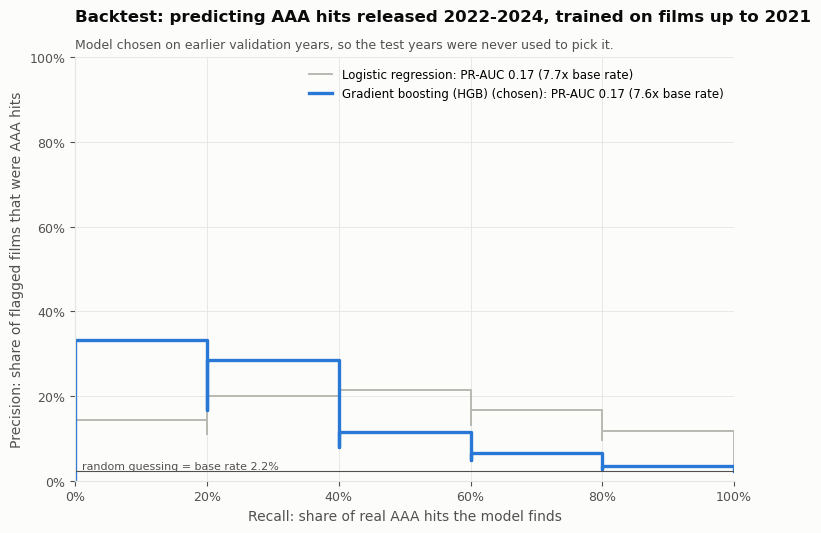

In [80]:
groups = space.groups()
bt = scorer.run_backtest(X.reset_index(drop=True), y, years, now, bcfg, groups)
print("Model choice (validation years):"); display(bt.selection)
print("Every candidate on the test years:"); display(bt.test)
bt.test.to_csv(TAB / "backtest_test_metrics.csv", index=False)
save(plots.plot_backtest(bt), "01_backtest_pr_curves")

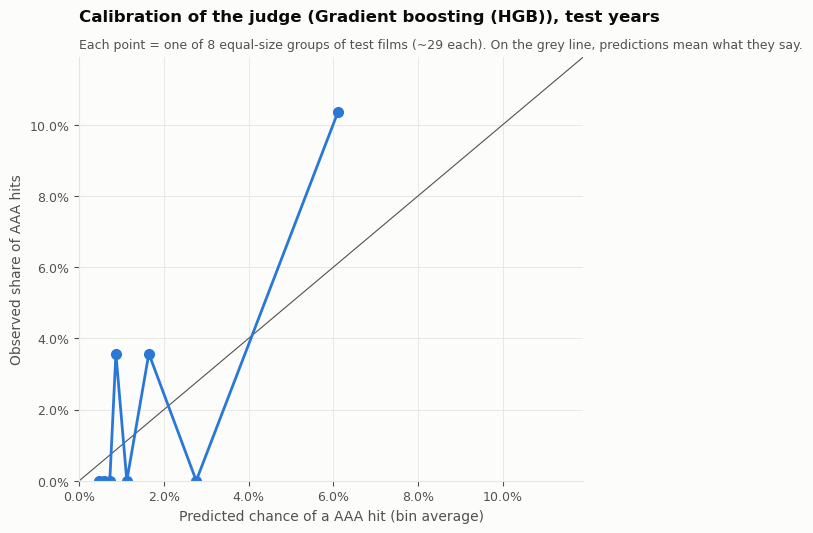

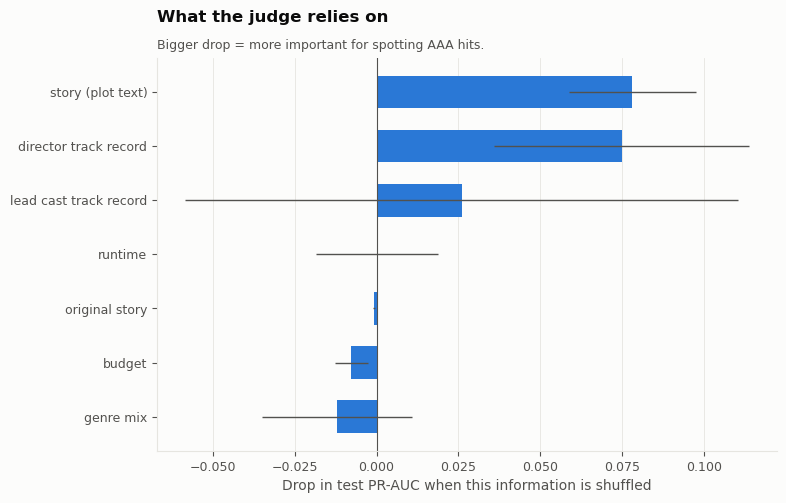

In [82]:
display(save(plots.plot_calibration(bt), "02_calibration"))
save(plots.plot_group_importance(bt.group_importance), "03_what_the_judge_uses")

**How to present this:** lead with *lift*, e.g. "the judge finds AAA hits at 6× the rate of picking films at random". Then show calibration, which is what lets us quote probabilities. Then show what it relies on. If TabPFN wins, that is the "beyond XGBoost" story with numbers behind it; if it doesn't, say so, and the novelty of the system is still the loop.

Now refit the chosen model on all years, with bootstrap copies for the uncertainty band. The familiarity scale is set by past **AAA-scale** films (budget ≥ $100M), because every concept is one.

In [90]:
aaa_scale = (X["log_budget"] >= np.log10(bcfg.min_budget_usd)).to_numpy()
judge = scorer.fit_judge(X, y, bt.chosen, bcfg, groups, ref_mask=aaa_scale)
print("Judge:", scorer.MODEL_LABELS[bt.chosen])

INFO nextaaa.partb.scorer: Judge refit on 7959 films (113 hits) with 5 bootstrap copies.


Judge: Gradient boosting (HGB)


## 5. The prompts, rendered

The evidence the generator sees comes straight from Part A: genre economics, recent AAA hits, and the talent tables. The JSON schema maps one-to-one onto the judge's features.

In [91]:
since = now - cfg.genre_recent_years + 1
genre_econ = hits.genre_economics(labels, since)
evidence = prompts.evidence_block(prompts.genre_table(genre_econ), prompts.recent_hits_table(labels, now - 9),
                                  prompts.talent_table(directors), prompts.talent_table(actors), since)
constraints = prompts.constraints_block(space.genres, bcfg)
islands = loop.lead_genres(genre_econ, bcfg.n_islands)
first = prompts.generate_prompt(evidence, constraints, bcfg.concepts_per_call, islands[0])
print("SYSTEM:\n" + first[0]["content"] + "\n\nUSER (first 3,500 characters):\n" + first[1]["content"][:3500] + " ...")

SYSTEM:
You are a development executive at a major film studio, pitching ORIGINAL feature-film concepts for a AAA slate. Original means: not a sequel, prequel, remake, reboot or spin-off, and not an adaptation of an existing book, comic, game, TV show or other franchise. Never copy an existing film; you may draw on the genres, structures and themes audiences have rewarded. You only cast directors and lead actors from the tables you are given, by their id. Reply with a single JSON object that matches the schema, and nothing else.

USER (first 3,500 characters):
## Goal
Propose 8 distinct concepts for an original AAA feature film that would be both an audience hit and a commercial hit.
Lead genre for this batch: Animation (combine it with other genres if that makes a stronger film).

## Evidence from our analysis
### Genre economics, films released 2011 onward (AAA hit = loved by audiences AND commercially successful in its year)
genre | films | AAA-hit rate | median ROI | median budget


Rounds 2 onward use the **refine** prompt: the same evidence, plus the best concepts so far listed **from lowest to highest** score (OPRO's design), each with its range and **drivers**, plus the concepts rejected for being too close to an existing film. You'll see a real one in section 6.

## 6. The loop, and the control arm

For each **island** (one lead genre each, from the genres with the highest recent AAA-hit rate; FunSearch-style islands keep the portfolio diverse):

1. round 1: the generate prompt → `concepts_per_call` concepts;
2. rounds 2…R: the refine prompt with the scored history;
3. every concept: **validate** (schema, real ids) → **novelty** (reject if its plot is closer to an existing film than 99% of real films are to their nearest neighbour; repeats of earlier concepts are rejected the same way) → **features** → **judge** → **drivers**.

**Familiarity guard:** a concept whose *invented* parts (genre mix, budget, runtime, story) are more unusual than 99% of past blockbusters is flagged. Its score counts half in the loop, and it can't enter the final portfolio, because the judge would be extrapolating.

**Control arm:** the same number of calls with the first-round prompt every time and **no feedback**. If the loop doesn't beat it, feedback adds nothing, and we say so.

In [97]:
film_titles = labels.loc[has_text, "primaryTitle"].to_numpy()
threshold = loop.nn_similarity_threshold(emb_text, bcfg.novelty_percentile)
ctx = loop.LoopContext(generator=clients.generator, embeddings=clients.embeddings, judge=judge, space=space,
                       directors=directors, actors=actors, film_emb=emb_text, film_titles=film_titles,
                       novelty_threshold=threshold, evidence=evidence, constraints=constraints,
                       allowed_genres=space.genres, bcfg=bcfg)
print(f"Islands: {islands}; novelty threshold (cosine): {threshold:.3f}")
arms = ["loop"] + (["no_feedback"] if bcfg.run_ablation else [])
recs = loop.run_arms(ctx, arms, islands)
concepts = pd.DataFrame(recs)
concepts.to_csv(TAB / "concepts_all.csv", index=False)
concepts["status"].value_counts().to_frame("concepts")

Islands: ['Animation', 'Sci-Fi', 'Horror']; novelty threshold (cosine): 0.805


INFO httpx2: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO nextaaa.partb.loop: l           island 3 (Horror) round 1: 8 scored, 0 rejected, best 0.054
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO nextaaa.partb.loop: l           island 2 (Sci-Fi) round 1: 8 scored, 0 re

RuntimeError: Embeddings: giving up after 5 attempts.

In [109]:
arms = ["loop"] + (["no_feedback"] if bcfg.run_ablation else [])
recs = loop.run_arms(ctx, arms, islands)
concepts = pd.DataFrame(recs)
concepts.to_csv(TAB / "concepts_all.csv", index=False)
concepts["status"].value_counts().to_frame("concepts")

INFO nextaaa.partb.loop: Starting 6 searches (loop+no_feedback x 3 islands), 30 generator calls, 6 at a time.
INFO nextaaa.partb.loop: loop island 1 (Animation) round 1: asking the generator...
INFO nextaaa.partb.loop: loop island 2 (Sci-Fi) round 1: asking the generator...
INFO nextaaa.partb.loop: loop island 3 (Horror) round 1: asking the generator...
INFO nextaaa.partb.loop: no_feedback island 1 (Animation) round 1: asking the generator...
INFO nextaaa.partb.loop: no_feedback island 2 (Sci-Fi) round 1: asking the generator...
INFO nextaaa.partb.loop: no_feedback island 3 (Horror) round 1: asking the generator...
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO httpx2: HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO httpx2

,concepts
status,
scored,237
rejected_repeat,3


C:\Users\user\Documents\next-aaa-title-part-a\next-aaa-title\src\nextaaa\partb\loop.py:244: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


arm,loop,no_feedback
round,,
1,0.050,0.052
2,0.057,0.057
3,0.060,0.058
4,0.061,0.058
5,0.061,0.058


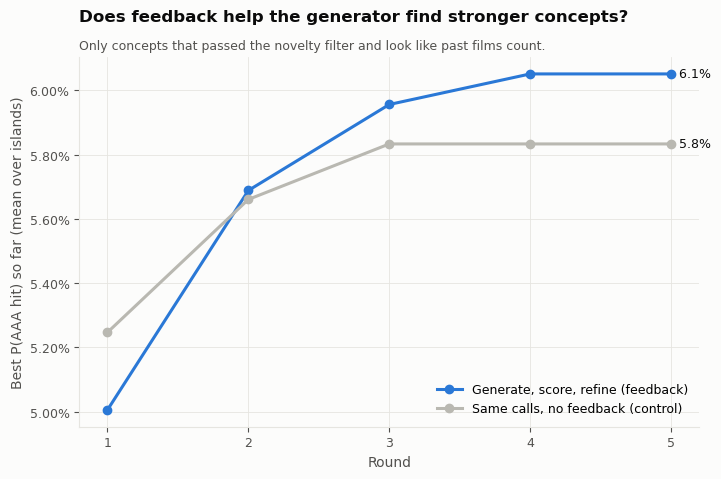

In [111]:
prog = loop.progress(concepts)
display(prog.pivot(index="round", columns="arm", values="best_so_far"))
save(plots.plot_loop_progress(prog), "04_loop_progress")

In [113]:
# A real refine prompt from the log (the last loop round of island 1):
import json
log = [json.loads(l) for l in open(OUT / "llm_log.jsonl", encoding="utf-8")]
refine = [r for r in log if r["purpose"].startswith("generate:loop:island1:round") and "LOWEST" in r["messages"][1]["content"]]
if refine:
    text = refine[-1]["messages"][1]["content"]
    print(text[: text.index("## Evidence")])

## Goal
Propose 8 NEW original AAA concepts that you expect to score higher than every concept below.
Lead genre for this batch: Animation.

## Concepts so far, from LOWEST to HIGHEST estimated chance of becoming a AAA hit
(score = calibrated chance of becoming a AAA hit, from a model trained on past films; the base rate for a film is a few percent. drivers = what raised (+) or lowered (-) each score most, in percentage points, compared with an average film)
[4.1% (range 5.4%-9.7%)] "Bridge the Sky": Animation/Adventure/Family | $155M | 108 min | dir D07 | leads A05, A39
    drivers: + director track record (+3.0 pts), + story (plot text) (+0.8 pts), + genre mix (+0.5 pts)
[4.2% (range 5.6%-15%)] "Star Camp": Animation/Adventure/Sci-Fi | $155M | 110 min | dir D04 | leads A05, A40
    drivers: + director track record (+3.1 pts), + genre mix (+1.4 pts), + story (plot text) (+0.9 pts)
[4.3% (range 9.7%-21%)] "The Red Tide": Animation/Action/Adventure | $155M | 114 min | dir D04 | leads A0

## 7. The pitch: the final portfolio

The best **familiar, original** concept per island (feedback arm), each with its calibrated chance of becoming a AAA hit, the bootstrap range, the drivers, and the closest existing film.

C:\Users\user\Documents\next-aaa-title-part-a\next-aaa-title\src\nextaaa\partb\loop.py:262: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


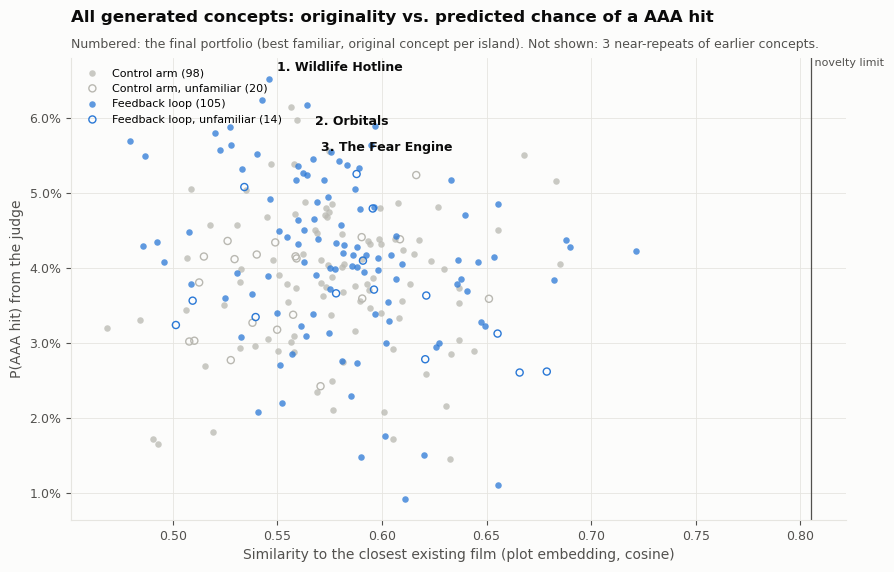

## 1. Wildlife Hotline

**A rookie raccoon answering an animal-run emergency line must guide hundreds of stranded creatures across a sleeping city before their last habitat is sealed off.**

Bix expects a quiet first shift taking calls from pets stuck in cupboards and pigeons lost at bus stations. Instead, a new construction barrier cuts off the narrow green route that urban wildlife has used for generations. Unable to reach the animals herself, Bix turns the hotline into a rescue network, pairing unlikely callers with jobs only they can do: a sewer-savvy turtle maps tunnels, while a vain rooftop cat scouts crossings. Her rule-following supervisor wants to shut down the chaos before humans notice. As sunrise approaches, Bix must trust her improvised team to move an entire community safely. The finale turns a bustling city into an exhilarating obstacle course and earns its warm payoff through collective ingenuity.

| | |
|---|---|
| Genres | Animation, Adventure, Comedy |
| Budget / runtime | $115M / 107 min |
| Director | Jonathan del Val (1 AAA hit in 2 films) |
| Leads | Ginnifer Goodwin (1 AAA hit in 4 films); Chris Pratt (3 AAA hits in 17 films) |
| Pitched against | The Secret Life of Pets, Zootopia |
| Why now | Its fast animal comedy comes with an accessible idea: even crowded cities can make room for their wild neighbors. |
| **P(AAA hit)** | **6.5%** (bootstrap range 5.7% to 29%) |
| Closest existing film | Over the Hedge (similarity 0.55) |
| Familiarity | more unusual than 47% of past films |

What drives the score:
  - raises the score: director track record (+4.6 percentage points)
  - raises the score: story (plot text) (+2.6 percentage points)
  - raises the score: genre mix (+1.3 percentage points)

## 2. Orbitals

**When a solar storm disables Earth's navigation network, two obsolete satellites become the only guides for a spacecraft full of children.**

Pip, an aging navigation satellite, is hours from being retired when a solar storm silences every newer system in orbit. A school spacecraft on its first trip beyond Earth is stranded, and Pip can hear its distress call. He recruits an argumentative weather satellite whose cameras can still see through the storm. Together they race around the planet, passing directions through forgotten machines while mission control struggles to understand who is helping. Each maneuver burns fuel they cannot replace. The satellites get the children home, then face one final choice: save themselves or keep the emergency network alive for everyone else.

| | |
|---|---|
| Genres | Sci-Fi, Animation, Adventure |
| Budget / runtime | $145M / 103 min |
| Director | Kyle Balda (3 AAA hits in 3 films) |
| Leads | Chris Pratt (3 AAA hits in 17 films); Idina Menzel (1 AAA hit in 3 films) |
| Pitched against | WALL-E, The Mitchells vs. the Machines |
| Why now | A funny, emotional space rescue makes the technology families rely on every day feel unexpectedly lovable. |
| **P(AAA hit)** | **6.2%** (bootstrap range 5.4% to 25%) |
| Closest existing film | Antariksham 9000 kmph (similarity 0.56) |
| Familiarity | more unusual than 91% of past films |

What drives the score:
  - raises the score: director track record (+4.6 percentage points)
  - raises the score: story (plot text) (+2.3 percentage points)
  - raises the score: genre mix (+1.2 percentage points)

## 3. The Fear Engine

**A theme park’s new ride reads guests’ fears, then turns them into creatures throughout the resort; its designer must guide her son through attractions that know them both.**

Ride designer June Mercer has built an attraction that adapts to each guest’s deepest fear. On opening night, a fault links it to every ride in the resort, and its inventions begin pursuing visitors beyond the tracks. June’s son, who helped test the system, realizes the creatures change when people confront rather than flee them. But the park has already learned June’s private fear: that saving the crowd will mean abandoning him. As emergency crews struggle to evacuate thousands of guests through attractions that keep redesigning themselves, June and her son travel back toward the central control room. Their victory requires a public admission of the safety shortcut June concealed, followed by one last ride together.

| | |
|---|---|
| Genres | Horror, Adventure, Action |
| Budget / runtime | $145M / 121 min |
| Director | David F. Sandberg (2 AAA hits in 5 films) |
| Leads | Bryce Dallas Howard (2 AAA hits in 9 films); Jaeden Martell (1 AAA hit in 10 films) |
| Pitched against | Jurassic Park, Poltergeist |
| Why now | The park setting promises distinct, trailer-ready scares while grounding its spectacle in a parent and child’s shared ordeal. |
| **P(AAA hit)** | **5.5%** (bootstrap range 16% to 42%) |
| Closest existing film | Malatesta's Carnival of Blood (similarity 0.57) |
| Familiarity | more unusual than 62% of past films |

What drives the score:
  - raises the score: story (plot text) (+2.0 percentage points)
  - raises the score: director track record (+1.3 percentage points)
  - lowers the score: genre mix (-0.2 percentage points)


In [115]:
final = loop.portfolio(concepts, bcfg.portfolio_size)
display(save(plots.plot_concept_map(concepts, final, threshold), "05_concept_map"))
cards = "\n".join(pitch_card(i, r, directors, actors) for i, (_, r) in enumerate(final.iterrows(), start=1))
if clients.mode == "mock":
    cards = "> **MOCK MODE**: placeholder concepts. Configure an LLM for real ones.\n\n" + cards
(OUT / "pitch_cards.md").write_text(cards, encoding="utf-8")
display(Markdown(cards))

**How to present a card:** "Concept 1 has an estimated X% chance of becoming a AAA hit (range Y to Z%), against a base rate of B% for films at this budget. What raises it: … What lowers it: … Closest existing film: …, at similarity S, below our novelty limit."

## 8. Baseline: can an LLM alone predict AAA hits?

Your original idea, tested fairly. The LLM (`BASELINE_MODEL`) sees the most similar **earlier** films with their outcomes (titles hidden), then a test film, and returns a probability. Only films released **after its knowledge cutoff** (`BASELINE_KNOWLEDGE_CUTOFF`) are tested, so it can't recall the answer. The judge is retrained on the same pre-cutoff films and scored on the same test films.

In [117]:
if bcfg.run_llm_baseline:
    preds, table = llm_baseline.run_llm_baseline(clients.judge, fin, X, emb[fin_mask], has_text[fin_mask],
                                                 bt.chosen, now, bcfg)
    if len(table):
        display(table)
        display(save(plots.plot_llm_vs_judge(preds, table), "06_llm_vs_judge"))

WARNING nextaaa.partb.llm_baseline: LLM baseline skipped: no post-cutoff test films with hits (cutoff 2024).


**How to read it:** compare PR-AUC first. The LLM saw a few extra hits in its examples, so its probabilities are not calibrated to the true base rate. If the LLM wins, that matches the UMAP 2025 finding that LLMs given metadata can rank new films well, and it argues for blending the two. If the judge wins, the division of labour is vindicated: the LLM creates, the trained model decides.

## 9. Cost, caveats, summary

In [119]:
clients.usage()

{'generator': {'calls': 115,
  'prompt_tokens': 454200,
  'completion_tokens': 448617},
 'judge': {'calls': 0, 'prompt_tokens': 0, 'completion_tokens': 0},
 'embeddings': {'calls': 254, 'texts': 37738}}

**Caveats to state on the slide**

- P(AAA hit) measures how strongly a concept resembles past AAA hits *under its pre-release facts*. It can't see the script, the marketing, competition, or release timing. It's a **triage tool for greenlighting**, not an oracle.
- Talent availability, fees and scheduling are not modelled. Naming real people is for the pitch's realism.
- Training uses past films, so the judge favours what has worked. The novelty filter and the familiarity guard keep the search honest, not adventurous; the generator supplies the originality.
- Budget and revenue come from TMDB, which is fullest for big, recent, English-language films. That's the right population for a AAA question, but not for indie films.

**Saved in `outputs/partb/`:** `pitch_cards.md`, `final_portfolio.json`, every concept, the backtest tables, six figures, and `llm_log.jsonl` (every prompt and reply, for the appendix).